In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from queries_sqlite3 import read_data

In [2]:
datasets = [
    "customers", 
    "order_payments", 
    "orders"
]

# Lê as três tabelas do banco SQLite para a exploração inicial.
tables = {
    name: read_data(name)
    for name in datasets
}

# Exploração geral

In [3]:
# Consolida dimensões, valores ausentes e duplicatas de cada tabela.
summary = []

for name, df in tables.items():
    summary.append({
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "missing_values": df.isnull().sum().sum(),
        "duplicate_rows": df.duplicated().sum()
    })

pd.DataFrame(summary)

,table,rows,columns,missing_values,duplicate_rows
0,customers,99441,5,0,0
1,order_payments,103886,5,0,0
2,orders,99441,8,4908,0


Exploração individual de cada conjunto de dados

# Clientes

In [4]:
customers = tables["customers"]

In [5]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [6]:
customers.sample(5)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
23022,54e217beb4b07ffdebc14c428e3f240d,1a431b876dce84b93132c2f8bf2701a0,17047,bauru,SP
70694,c36b6c328033cca3190e0e45ee61b010,c1051761919d37d096f281b050c5b5e8,42808,camacari,BA
15052,1ea8e45ffebf367b2f046c8b3c8ff230,bc5b38c4913692426b92b0d40a6ddc1f,1030,sao paulo,SP
48381,a5347c1cc1b3e01cce8d58574f6a7210,2b4ac15332225168fe3a3ddd4031275b,22790,rio de janeiro,RJ
65252,f1dbd5b4e2100112b354805ad704e604,f8f1963398b95ea31797dcb821ba8541,36460,rio espera,MG


In [7]:
customers.shape

(99441, 5)

In [8]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [9]:
customers.describe()

,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000


In [10]:
customers.describe(include="object")

,customer_id,customer_unique_id,customer_city,customer_state
count,99441,99441,99441,99441
unique,99441,96096,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,sao paulo,SP
freq,1,17,15540,41746


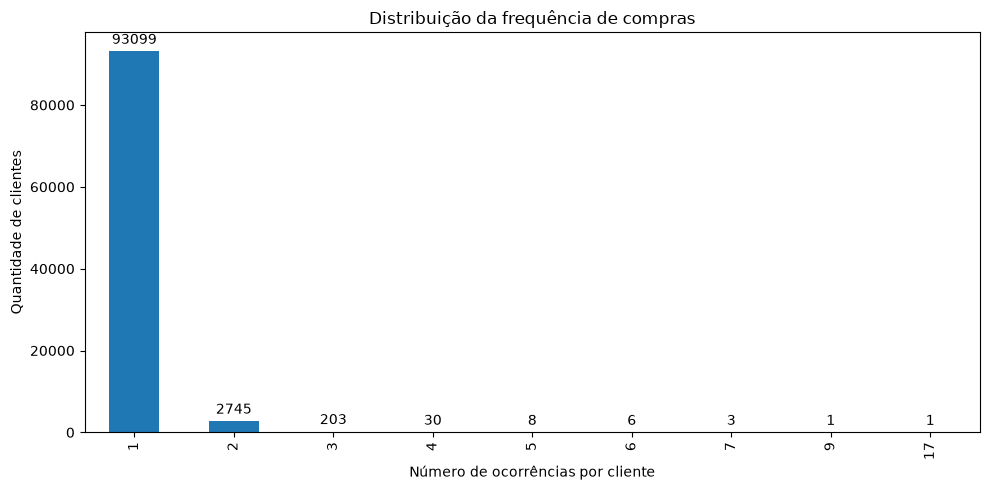

In [11]:
frequencia = customers["customer_unique_id"].value_counts()

ax = frequencia.value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribuição da frequência de compras")
plt.xlabel("Número de ocorrências por cliente")
plt.ylabel("Quantidade de clientes")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
plt.tight_layout()
plt.show()

# Pedidos

In [12]:
orders = tables["orders"]

## Exploração Geral

In [13]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [14]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [15]:
orders.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [16]:
order_purchase_timestamp = pd.to_datetime(orders["order_purchase_timestamp"])
print(order_purchase_timestamp.dt.year.unique())

[2017 2018 2016]


Os dados abrangem três anos distintos.

In [17]:
orders["order_status"].unique()

array(['delivered', 'invoiced', 'shipped', 'processing', 'unavailable',
       'canceled', 'created', 'approved'], dtype=object)

In [18]:
title_date_columns = ["order_purchase_timestamp", 
            "order_approved_at", 
            "order_delivered_carrier_date", 
            "order_delivered_customer_date", 
            "order_estimated_delivery_date"]

for col in title_date_columns:
    print(f"Coluna: {col}")
    column = pd.to_datetime(orders[col])
    print(f'Inicio: {column.min()} e Fim: {column.max()}')
    print("\n")

Coluna: order_purchase_timestamp
Inicio: 2016-09-04 21:15:19 e Fim: 2018-10-17 17:30:18


Coluna: order_approved_at
Inicio: 2016-09-15 12:16:38 e Fim: 2018-09-03 17:40:06


Coluna: order_delivered_carrier_date
Inicio: 2016-10-08 10:34:01 e Fim: 2018-09-11 19:48:28


Coluna: order_delivered_customer_date
Inicio: 2016-10-11 13:46:32 e Fim: 2018-10-17 13:22:46


Coluna: order_estimated_delivery_date
Inicio: 2016-09-30 00:00:00 e Fim: 2018-11-12 00:00:00




In [19]:
print(f"{len(orders.loc[orders["order_status"] == "delivered"]) / len(orders) * 100:.2f}% dos pedidos foram entregues.") 

97.02% dos pedidos foram entregues.


## Exploração de valores ausentes

In [20]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [21]:
orders.loc[orders["order_status"] != "canceled"].isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  19
order_delivered_carrier_date     1233
order_delivered_customer_date    2346
order_estimated_delivery_date       0
dtype: int64

Nem todos os pedidos com valores ausentes foram cancelados.

In [22]:
filter_null = orders.isnull().any(axis=1)
orders[filter_null]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,None,None,2017-05-09 00:00:00
44,ee64d42b8cf066f35eac1cf57de1aa85,caded193e8e47b8362864762a83db3c5,shipped,2018-06-04 16:44:48,2018-06-05 04:31:18,2018-06-05 14:32:00,None,2018-06-28 00:00:00
103,0760a852e4e9d89eb77bf631eaaf1c84,d2a79636084590b7465af8ab374a8cf5,invoiced,2018-08-03 17:44:42,2018-08-07 06:15:14,None,None,2018-08-21 00:00:00
128,15bed8e2fec7fdbadb186b57c46c92f2,f3f0e613e0bdb9c7cee75504f0f90679,processing,2017-09-03 14:22:03,2017-09-03 14:30:09,None,None,2017-10-03 00:00:00
154,6942b8da583c2f9957e990d028607019,52006a9383bf149a4fb24226b173106f,shipped,2018-01-10 11:33:07,2018-01-11 02:32:30,2018-01-11 19:39:23,None,2018-02-07 00:00:00
...,...,...,...,...,...,...,...,...
99283,3a3cddda5a7c27851bd96c3313412840,0b0d6095c5555fe083844281f6b093bb,canceled,2018-08-31 16:13:44,None,None,None,2018-10-01 00:00:00
99313,e9e64a17afa9653aacf2616d94c005b8,b4cd0522e632e481f8eaf766a2646e86,processing,2018-01-05 23:07:24,2018-01-09 07:18:05,None,None,2018-02-06 00:00:00
99347,a89abace0dcc01eeb267a9660b5ac126,2f0524a7b1b3845a1a57fcf3910c4333,canceled,2018-09-06 18:45:47,None,None,None,2018-09-27 00:00:00
99348,a69ba794cc7deb415c3e15a0a3877e69,726f0894b5becdf952ea537d5266e543,unavailable,2017-08-23 16:28:04,2017-08-28 15:44:47,None,None,2017-09-15 00:00:00


In [23]:
len(orders[filter_null])

2980

In [24]:
len(orders.loc[
    filter_null
    & (orders["order_status"] != "delivered")
])

2957

In [25]:
len(orders.loc[
    filter_null
    & (orders["order_status"] == "delivered")
])

23

Dos 2.980 pedidos com valores ausentes, apenas 23 foram entregues. Como esse total representa uma pequena parcela das aproximadamente 100 mil instâncias e, na análise de receita a seguir, esses pedidos não devem afetar a distribuição dos dados, podemos desconsiderar os pedidos com valores ausentes cujo status seja diferente de "delivered".

In [26]:
orders.loc[
    ~filter_null
    & (orders["order_status"] != "delivered")
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
2921,1950d777989f6a877539f53795b4c3c3,1bccb206de9f0f25adc6871a1bcf77b2,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09 00:00:00
8791,dabf2b0e35b423f94618bf965fcb7514,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30 00:00:00
58266,770d331c84e5b214bd9dc70a10b829d0,6c57e6119369185e575b36712766b0ef,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29 00:00:00
59332,8beb59392e21af5eb9547ae1a9938d06,bf609b5741f71697f65ce3852c5d2623,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30 00:00:00
92636,65d1e226dfaeb8cdc42f665422522d14,70fc57eeae292675927697fe03ad3ff5,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25 00:00:00
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,de4caa97afa80c8eeac2ff4c8da5b72e,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08 00:00:00


Entre as instâncias com status diferente de "delivered", restam apenas seis sem valores ausentes; todas foram canceladas e, portanto, não serão consideradas na análise de receita. Assim, podemos usar o status diferente de "delivered" como critério para excluir os registros com valores ausentes. Esse critério também remove os pedidos cancelados, que não devem ser contabilizados na análise. As demais categorias de status, como pedidos em processamento, não são relevantes para esse recorte.

A remoção de 2.963 instâncias com status diferente de "delivered" corresponde a 2,98% do total. Como essa parcela é pequena, a análise exploratória considera que sua remoção não deve afetar a distribuição dos dados. Esse filtro é aplicado antes da análise de receita em `analysis.ipynb`, por meio da função `create_view_cleaned_data()`, chamada por `main.py` e definida em `analytics/queries_sqlite3.py`.

## Exploração dos limites temporais do conjunto de dados

/tmp/ipykernel_34399/974547741.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


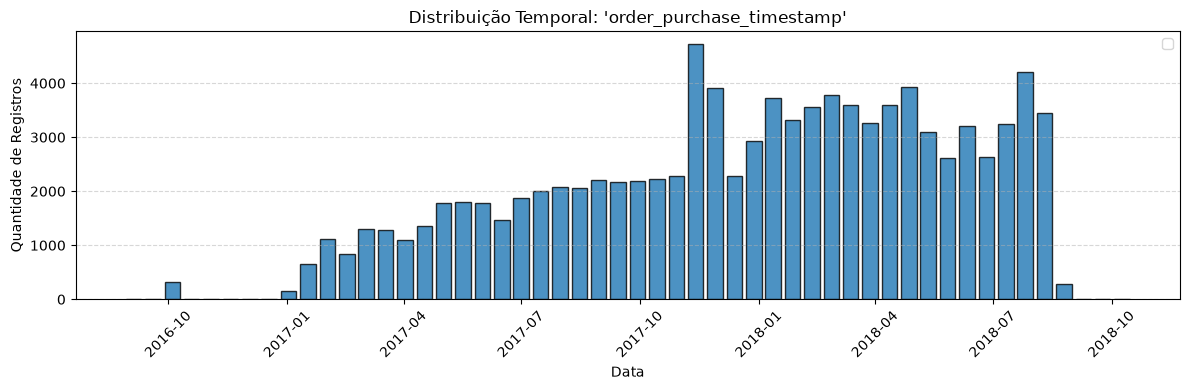

/tmp/ipykernel_34399/974547741.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


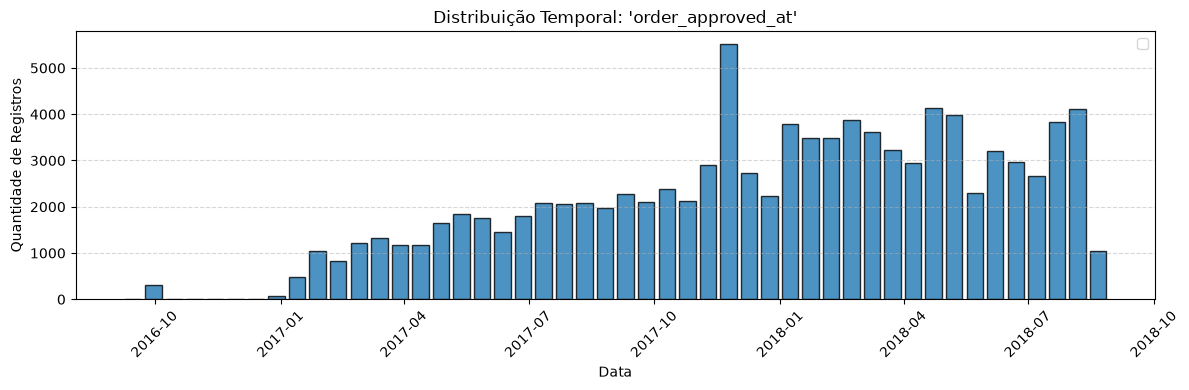

/tmp/ipykernel_34399/974547741.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


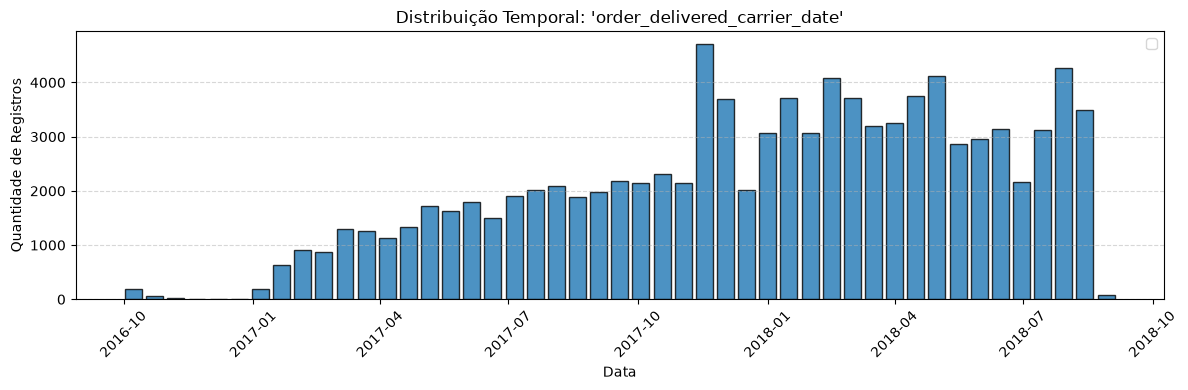

/tmp/ipykernel_34399/974547741.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


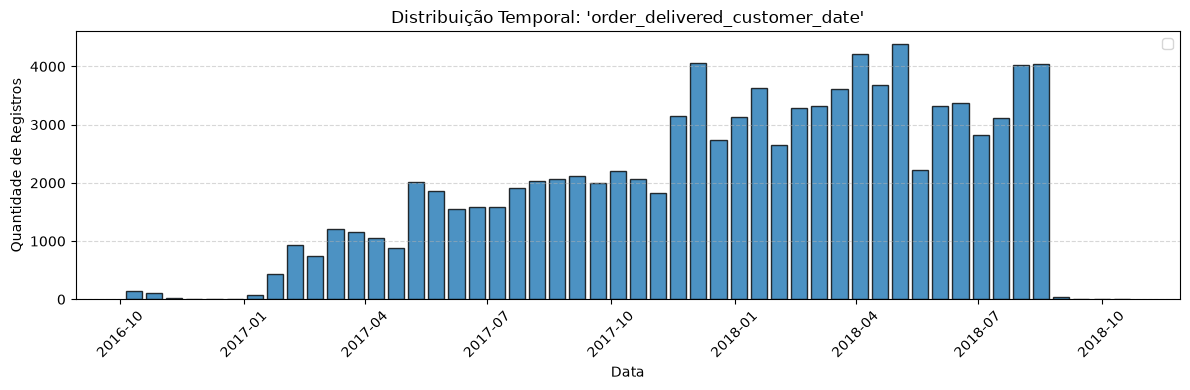

/tmp/ipykernel_34399/974547741.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


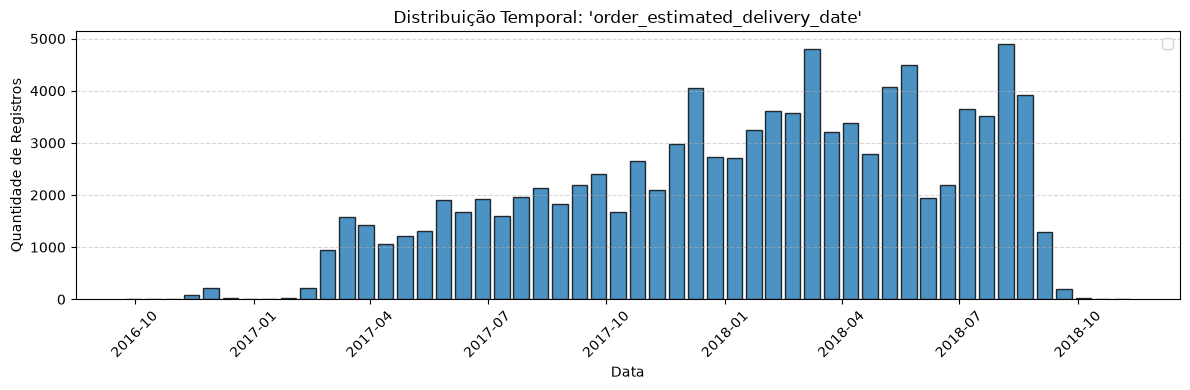

In [27]:
frequencia = "15D"

for col in title_date_columns:

    orders[col] = pd.to_datetime(orders[col], errors="coerce")

    df_filtered = orders.dropna(subset=[col]).copy()

    if df_filtered.empty:
        continue

    time_series = (
        df_filtered
        .set_index(col)
        .resample(frequencia)
        .size()
    )

    plt.figure(figsize=(12, 4))

    plt.bar(
        time_series.index,
        time_series.values,
        width=12,
        color="#1f77b4",
        edgecolor="black",
        alpha=0.8
    )

    plt.title(f"Distribuição Temporal: '{col}'", fontsize=12)
    plt.xlabel("Data")
    plt.ylabel("Quantidade de Registros")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Há dois períodos de instabilidade nos registros dos pedidos: um no início da plataforma e outro no final, provavelmente devido a truncamentos nos dados. Vou investigar em que datas esses truncamentos ocorreram.

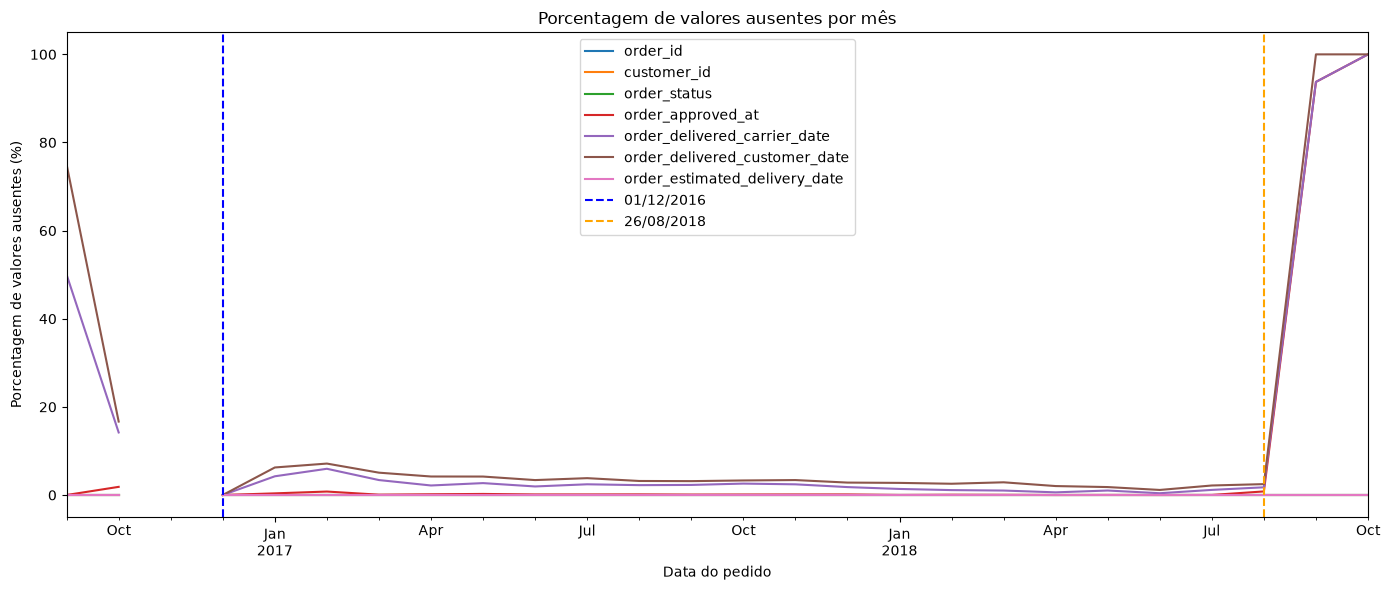

In [28]:
missing = orders.set_index('order_purchase_timestamp')

missing = (
    missing.isnull()
    .resample('ME')
    .mean() * 100
)

ax = missing.plot(figsize=(14, 6))

# Linha vertical no inicio
ax.axvline(
    pd.Timestamp('2016-12-01'),
    color='blue',
    linestyle='--',
    linewidth=1.5,
    label='01/12/2016'
)

# Linha vertical no final
ax.axvline(
    pd.Timestamp('2018-08-26'),
    color='orange',
    linestyle='--',
    linewidth=1.5,
    label='26/08/2018'
)

# Títulos dos eixos
ax.set_xlabel('Data do pedido')
ax.set_ylabel('Porcentagem de valores ausentes (%)')

# Título do gráfico
ax.set_title('Porcentagem de valores ausentes por mês')

ax.legend()
plt.tight_layout()
plt.show()

Durante a análise exploratória, foi identificada instabilidade nos registros anteriores a dezembro de 2016 e posteriores a 19/08/2018. Para assegurar a validade das análises seguintes, esses dois períodos serão removidos. Em particular, observa-se uma redução significativa na quantidade de pedidos e um aumento na proporção de pedidos ainda não concluídos e de valores ausentes após 26/08/2018, próximo ao final do período analisado.

Esse comportamento sugere uma possível interrupção ou truncamento na disponibilização dos dados, fazendo com que os registros desse intervalo apresentem informações incompletas.

A manutenção dessas observações poderia comprometer a confiabilidade das análises temporais, introduzindo possíveis vieses nos indicadores de desempenho e dificultando a comparação entre diferentes períodos. Como será realizada uma análise de receita, esse recorte pode gerar alguns problemas:

- Viés temporal: os últimos períodos podem não representar adequadamente o comportamento real das vendas.

- Inconsistência na análise: indicadores como faturamento, volume de pedidos e avaliações podem apresentar distorções.

- Comparabilidade: comparar períodos completos com períodos parcialmente registrados pode levar a conclusões equivocadas.

Essa decisão busca preservar a qualidade dos dados e aumentar a confiabilidade das conclusões do projeto.
O filtro utilizado na análise também é aplicado pela função `create_view_cleaned_data()`, definida em `analytics/queries_sqlite3.py` e chamada por `main.py`.

In [29]:
# Aplicação dos filtros
# Restringe a exploração aos pedidos entregues no intervalo temporal selecionado.
filter_delivered = orders["order_status"] == "delivered"
filter_initial = orders["order_purchase_timestamp"] >= "2016-12-01"
filter_final = orders["order_purchase_timestamp"] <= "2018-08-26"

filter = filter_delivered & filter_initial & filter_final

orders = orders.loc[filter].copy()

Observação: o filtro por status diferente de "delivered" é adequado ao escopo da análise de receita, pois os demais status não serão considerados.

In [30]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
Index: 96023 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96023 non-null  object        
 1   customer_id                    96023 non-null  object        
 2   order_status                   96023 non-null  object        
 3   order_purchase_timestamp       96023 non-null  datetime64[ns]
 4   order_approved_at              96009 non-null  datetime64[ns]
 5   order_delivered_carrier_date   96021 non-null  datetime64[ns]
 6   order_delivered_customer_date  96015 non-null  datetime64[ns]
 7   order_estimated_delivery_date  96023 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.6+ MB


# Pagamentos dos pedidos

In [31]:
order_payments = tables["order_payments"]

In [32]:
order_payments

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
...,...,...,...,...,...
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54


In [33]:
order_payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [34]:
order_payments.sample(10)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
93188,cdf9aa68e72324eeb25c7de974696ee2,1,credit_card,1,136.99
6016,c8de7919d8d79c2bb4bb86e34697039d,1,credit_card,2,68.68
80810,6f516d489f56fd8bc9d89e9e62c00d2c,1,credit_card,8,176.65
94523,674957a5e7051291e2b937c5867a06b4,1,credit_card,1,129.43
65991,475066321e4cc5faaa72747dcbda1804,1,credit_card,4,227.01
49205,ecc812c240c4f03824a3c5d7e3b6d351,1,credit_card,1,96.12
87299,fec4d19f04178e4adbe16ebfc8c7ebd7,1,credit_card,10,227.27
95426,0e3077db347b6985225369e7fb0b8120,1,boleto,1,58.62
18561,20e223f06b4ead7a6d8ed147dae59b12,1,boleto,1,75.08
10038,21c8e489ad81de6c543c6e3964f8038f,1,credit_card,1,27.77


In [35]:
order_payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [36]:
order_payments.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [37]:
order_payments.describe(include="object")

,order_id,payment_type
count,103886,103886
unique,99440,5
top,fa65dad1b0e818e3ccc5cb0e39231352,credit_card
freq,29,76795


In [38]:
order_payments[order_payments["order_id"] == "fa65dad1b0e818e3ccc5cb0e39231352"]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
4885,fa65dad1b0e818e3ccc5cb0e39231352,27,voucher,1,66.02
9985,fa65dad1b0e818e3ccc5cb0e39231352,4,voucher,1,29.16
14321,fa65dad1b0e818e3ccc5cb0e39231352,1,voucher,1,3.71
17274,fa65dad1b0e818e3ccc5cb0e39231352,9,voucher,1,1.08
19565,fa65dad1b0e818e3ccc5cb0e39231352,10,voucher,1,12.86
23074,fa65dad1b0e818e3ccc5cb0e39231352,2,voucher,1,8.51
24879,fa65dad1b0e818e3ccc5cb0e39231352,25,voucher,1,3.68
28330,fa65dad1b0e818e3ccc5cb0e39231352,5,voucher,1,0.66
29648,fa65dad1b0e818e3ccc5cb0e39231352,6,voucher,1,5.02
32519,fa65dad1b0e818e3ccc5cb0e39231352,11,voucher,1,4.03


In [39]:
order_payments.nunique()

order_id                99440
payment_sequential         29
payment_type                5
payment_installments       24
payment_value           29077
dtype: int64

In [40]:
order_payments["payment_sequential"].value_counts()

payment_sequential
1     99360
2      3039
3       581
4       278
5       170
6       118
7        82
8        54
9        43
10       34
11       29
12       21
13       13
14       10
15        8
17        6
19        6
18        6
16        6
20        4
21        4
22        3
24        2
25        2
26        2
23        2
27        1
28        1
29        1
Name: count, dtype: int64

In [41]:
order_payments["payment_type"].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [42]:
order_payments["payment_installments"].value_counts()

payment_installments
1     52546
2     12413
3     10461
4      7098
10     5328
5      5239
8      4268
6      3920
7      1626
9       644
12      133
15       74
18       27
11       23
24       18
20       17
13       16
14       15
17        8
16        5
21        3
0         2
22        1
23        1
Name: count, dtype: int64

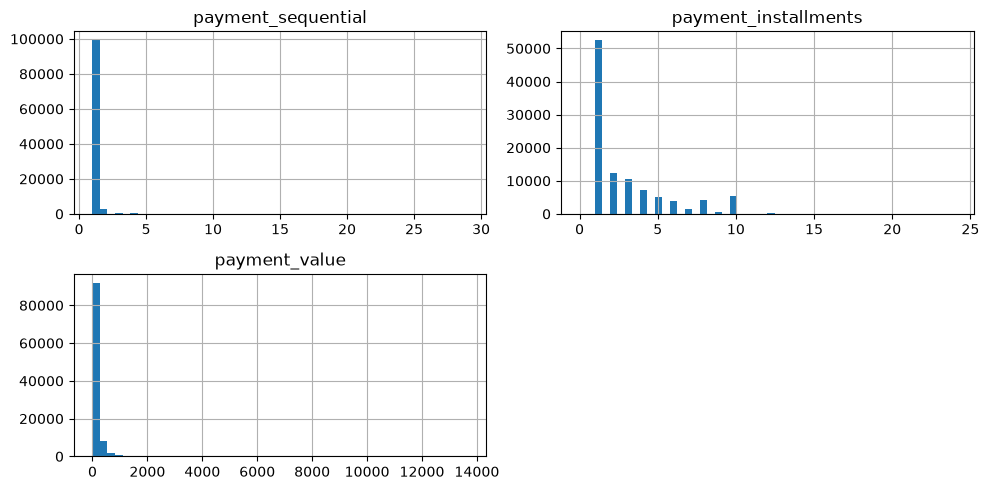

In [43]:
order_payments.hist(figsize=(10, 5), bins=50)
plt.tight_layout()
plt.show()

Os histogramas mostram que não há valores negativos, o que seria inadmissível em variáveis como valor do pagamento, número de parcelas e sequência do pagamento.

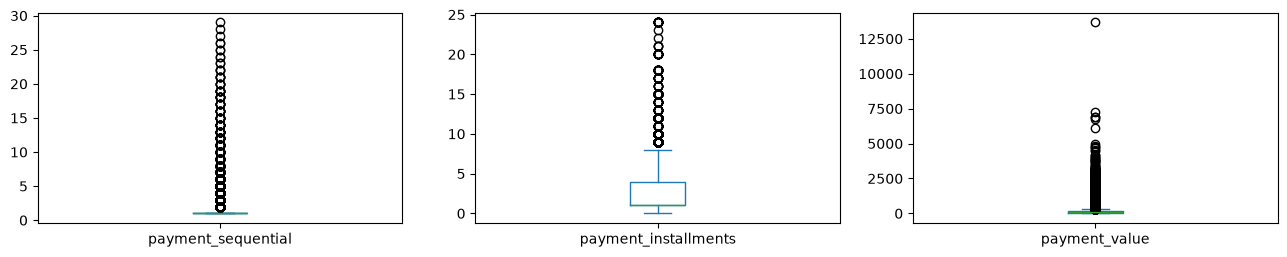

In [44]:
order_payments.plot(kind="box", subplots=True, layout=(2, 3), figsize=(16, 6), sharex=False)
plt.show()

In [45]:
order_payments[order_payments["payment_value"] < 0] # Não há preços negativos

,order_id,payment_sequential,payment_type,payment_installments,payment_value
